# TASK 4: CUSTOMER DATA ANALYSIS


## 1. Import libraries

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)


## 2. Load customer dataset

In [2]:
CSV_FILE = "customer_data_synthetic.csv"
if not Path(CSV_FILE).exists():
    raise FileNotFoundError("Put customer_data_synthetic.csv in the same folder as this notebook.")
raw_data = pd.read_csv(CSV_FILE)
print("Dataset shape:", raw_data.shape)
display(raw_data.head())

Dataset shape: (1208, 12)


,transaction_id,customer_id,age,gender,city,product_category,quantity,unit_price,discount_percent,purchase_amount,purchase_date,payment_method
0,T00001,C0269,47,Female,Pune,Clothing,3,720.60,0.0,2161.80,2025-04-01,UPI
1,T00002,C0089,54,Female,Kolkata,Groceries,1,468.41,15.0,398.15,2025-07-16,Debit Card
2,T00003,C0055,41,Female,Kolkata,Clothing,4,1346.15,0.0,5384.60,2025-07-28,UPI
3,T00004,C0041,25,Female,Pune,Groceries,2,309.25,0.0,618.50,2026-05-26,Credit Card
4,T00005,C0235,41,Female,Hyderabad,Beauty,1,595.19,15.0,505.91,2025-07-21,UPI


## 3. Inspect dataset and data quality

In [3]:
print("Columns:", raw_data.columns.tolist())
raw_data.info()
print("\nMissing values:")
display(raw_data.isna().sum().to_frame("missing_values"))
print("\nDuplicate rows:", raw_data.duplicated().sum())

Columns: ['transaction_id', 'customer_id', 'age', 'gender', 'city', 'product_category', 'quantity', 'unit_price', 'discount_percent', 'purchase_amount', 'purchase_date', 'payment_method']
<class 'pandas.DataFrame'>
RangeIndex: 1208 entries, 0 to 1207
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    1208 non-null   str    
 1   customer_id       1208 non-null   str    
 2   age               1208 non-null   int64  
 3   gender            1199 non-null   str    
 4   city              1208 non-null   str    
 5   product_category  1208 non-null   str    
 6   quantity          1208 non-null   int64  
 7   unit_price        1208 non-null   float64
 8   discount_percent  1204 non-null   float64
 9   purchase_amount   1208 non-null   float64
 10  purchase_date     1208 non-null   str    
 11  payment_method    1201 non-null   str    
dtypes: float64(3), int64(2), str(7)
memory usage: 170.8 K

,missing_values
transaction_id,0
customer_id,0
age,0
gender,9
city,0
product_category,0
quantity,0
unit_price,0
discount_percent,4
purchase_amount,0



Duplicate rows: 8


## 4. Clean and prepare data

In [4]:
data = raw_data.copy()
data.columns = data.columns.str.strip().str.lower()
data = data.drop_duplicates()
for col in data.select_dtypes(include=["object"]).columns:
    data[col] = data[col].astype("string").str.strip()
for col in ["age","quantity","unit_price","discount_percent","purchase_amount"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data["purchase_date"] = pd.to_datetime(data["purchase_date"], errors="coerce")
for col in ["gender","payment_method"]:
    if data[col].isna().any():
        data[col] = data[col].fillna(data[col].mode().iloc[0])
data["discount_percent"] = data["discount_percent"].fillna(data["discount_percent"].median())
data = data.dropna(subset=["customer_id","age","city","product_category","quantity","unit_price","purchase_amount","purchase_date"])
print("Cleaned shape:", data.shape)
print("Missing cells remaining:", data.isna().sum().sum())
print("Duplicate rows remaining:", data.duplicated().sum())
display(data.head())

Cleaned shape: (1200, 12)
Missing cells remaining: 0
Duplicate rows remaining: 0


C:\Users\matiu\AppData\Local\Temp\ipykernel_13080\4170102914.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in data.select_dtypes(include=["object"]).columns:


,transaction_id,customer_id,age,gender,city,product_category,quantity,unit_price,discount_percent,purchase_amount,purchase_date,payment_method
0,T00001,C0269,47,Female,Pune,Clothing,3,720.60,0.0,2161.80,2025-04-01,UPI
1,T00002,C0089,54,Female,Kolkata,Groceries,1,468.41,15.0,398.15,2025-07-16,Debit Card
2,T00003,C0055,41,Female,Kolkata,Clothing,4,1346.15,0.0,5384.60,2025-07-28,UPI
3,T00004,C0041,25,Female,Pune,Groceries,2,309.25,0.0,618.50,2026-05-26,Credit Card
4,T00005,C0235,41,Female,Hyderabad,Beauty,1,595.19,15.0,505.91,2025-07-21,UPI


## 5. Purchasing behaviour analysis

In [5]:
total_revenue = data["purchase_amount"].sum()
total_orders = data["transaction_id"].nunique()
unique_customers = data["customer_id"].nunique()
print(f"Total revenue: ₹{total_revenue:,.2f}")
print(f"Transactions: {total_orders:,}")
print(f"Unique customers: {unique_customers:,}")
print(f"Average transaction value: ₹{data['purchase_amount'].mean():,.2f}")
category_summary = data.groupby("product_category").agg(
    orders=("transaction_id","nunique"), revenue=("purchase_amount","sum"),
    quantity=("quantity","sum")).sort_values("revenue",ascending=False)
display(category_summary)

Total revenue: ₹7,315,685.98
Transactions: 1,200
Unique customers: 285
Average transaction value: ₹6,096.40


,orders,revenue,quantity
product_category,,,
Electronics,196,4369668.18,507
Home & Kitchen,151,987373.26,374
Clothing,305,895987.43,739
Sports,85,376114.60,219
Groceries,308,344166.40,777
Beauty,155,342376.11,408


## 6. Customer segmentation by age

In [6]:
bins=[17,25,35,45,55,100]
labels=["18–25","26–35","36–45","46–55","56+"]
data["age_group"]=pd.cut(data["age"],bins=bins,labels=labels)
age_summary=data.groupby("age_group",observed=False).agg(
    customers=("customer_id","nunique"),transactions=("transaction_id","nunique"),
    revenue=("purchase_amount","sum")).reset_index()
display(age_summary)

,age_group,customers,transactions,revenue
0,18–25,48,210,1208260.14
1,26–35,53,211,1375148.98
2,36–45,71,279,1612094.72
3,46–55,68,298,1917654.74
4,56+,45,202,1202527.40


## 7. Customer segmentation by location

In [7]:
city_summary=data.groupby("city").agg(
    customers=("customer_id","nunique"),transactions=("transaction_id","nunique"),
    revenue=("purchase_amount","sum")).sort_values("revenue",ascending=False)
display(city_summary)

,customers,transactions,revenue
city,,,
Mumbai,37,186,1180391.28
Hyderabad,31,178,1123087.42
Delhi,39,162,990842.52
Kolkata,46,178,976167.48
Lucknow,42,155,946235.18
Pune,31,110,813352.23
Jaipur,35,134,758189.04
Bengaluru,24,97,527420.83


## 8. Identify valuable customer groups

In [8]:
customer_summary=data.groupby("customer_id").agg(
    age=("age","first"),city=("city","first"),gender=("gender","first"),
    transactions=("transaction_id","nunique"),total_spend=("purchase_amount","sum"),
    avg_order_value=("purchase_amount","mean"),last_purchase=("purchase_date","max")).reset_index()
q1,q2=customer_summary["total_spend"].quantile([.50,.80])
customer_summary["value_segment"]=np.select(
    [customer_summary["total_spend"]>=q2,customer_summary["total_spend"]>=q1],
    ["High Value","Medium Value"],default="Low Value")
segment_summary=customer_summary.groupby("value_segment").agg(
    customers=("customer_id","count"),average_spend=("total_spend","mean"),
    total_revenue=("total_spend","sum")).sort_values("average_spend",ascending=False)
display(segment_summary)
display(customer_summary.nlargest(10,"total_spend"))

,customers,average_spend,total_revenue
value_segment,,,
High Value,57,68337.171053,3895218.75
Medium Value,86,27605.343605,2374059.55
Low Value,142,7369.068169,1046407.68


,customer_id,age,city,gender,transactions,total_spend,avg_order_value,last_purchase,value_segment
188,C0197,34,Lucknow,Female,10,167052.96,16705.296000,2026-09-03,High Value
105,C0111,31,Delhi,Male,15,154414.26,10294.284000,2026-10-10,High Value
256,C0270,46,Hyderabad,Male,23,136774.52,5946.718261,2026-09-29,High Value
15,C0016,55,Pune,Female,13,131925.15,10148.088462,2026-10-16,High Value
186,C0195,64,Mumbai,Male,13,130373.65,10028.742308,2026-10-01,High Value
104,C0110,51,Lucknow,Other,5,119084.49,23816.898000,2026-10-28,High Value
94,C0100,24,Mumbai,Female,20,118347.51,5917.375500,2026-10-05,High Value
247,C0261,56,Hyderabad,Female,6,110922.28,18487.046667,2026-07-30,High Value
78,C0083,25,Kolkata,Male,3,108315.83,36105.276667,2026-09-14,High Value
69,C0074,24,Mumbai,Female,13,103499.85,7961.526923,2026-08-02,High Value


## 9. Visual reports

### 9.1 Bar chart: revenue by product category

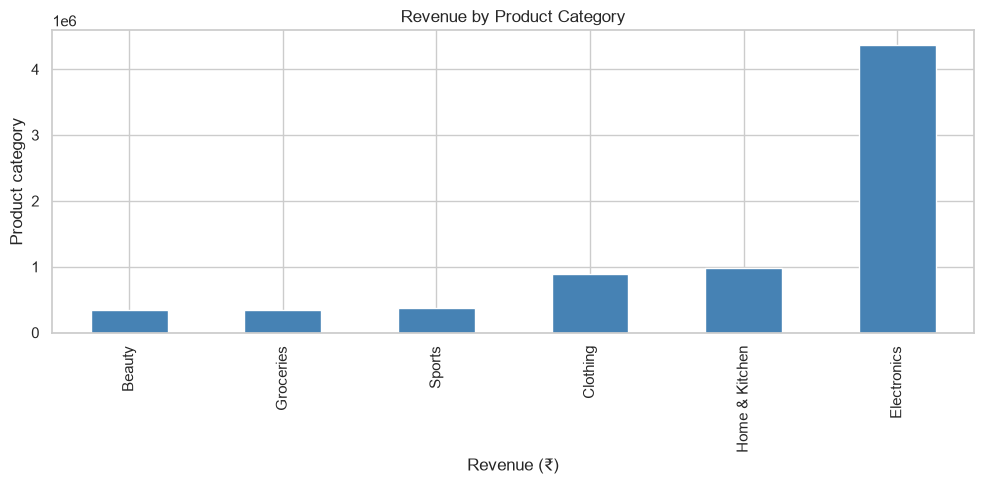

In [10]:
category_summary["revenue"].sort_values().plot(kind="bar",color="steelblue",title="Revenue by Product Category")
plt.xlabel("Revenue (₹)"); plt.ylabel("Product category"); plt.tight_layout(); plt.show()

### 9.2 Pie chart: customer value segments

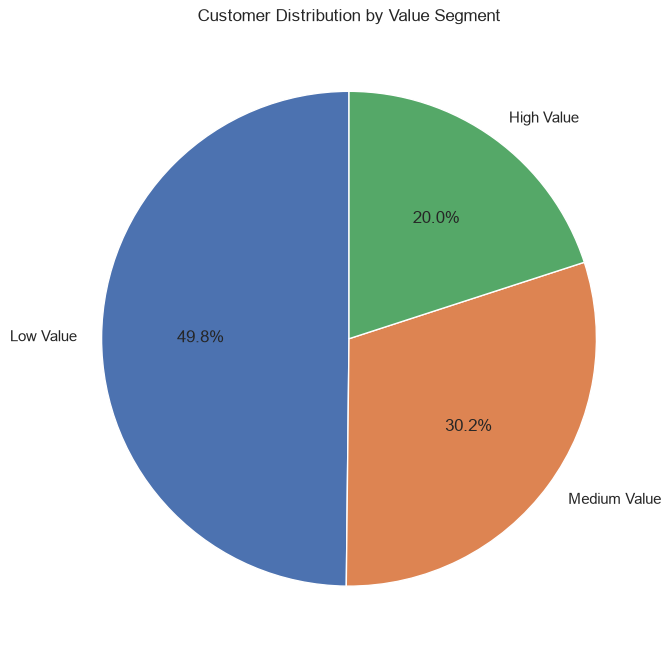

In [12]:
counts=customer_summary["value_segment"].value_counts()
plt.figure(figsize=(7,7)); plt.pie(counts,labels=counts.index,autopct="%1.1f%%",startangle=90)
plt.title("Customer Distribution by Value Segment"); plt.tight_layout(); plt.show()

### 9.3 Histogram: customer age distribution

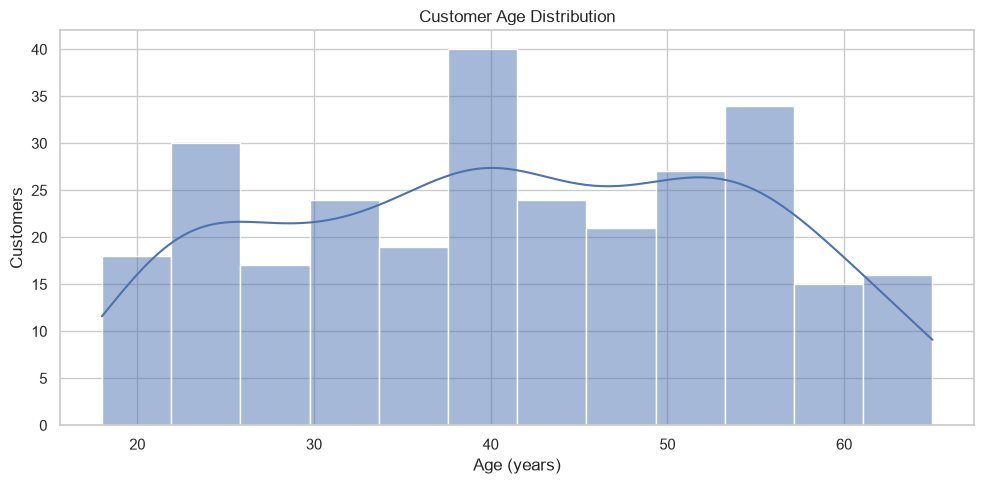

In [13]:
one_per_customer=data.drop_duplicates("customer_id")
sns.histplot(data=one_per_customer,x="age",bins=12,kde=True)
plt.title("Customer Age Distribution"); plt.xlabel("Age (years)"); plt.ylabel("Customers")
plt.tight_layout(); plt.show()

### 9.4 Bar chart: revenue by city

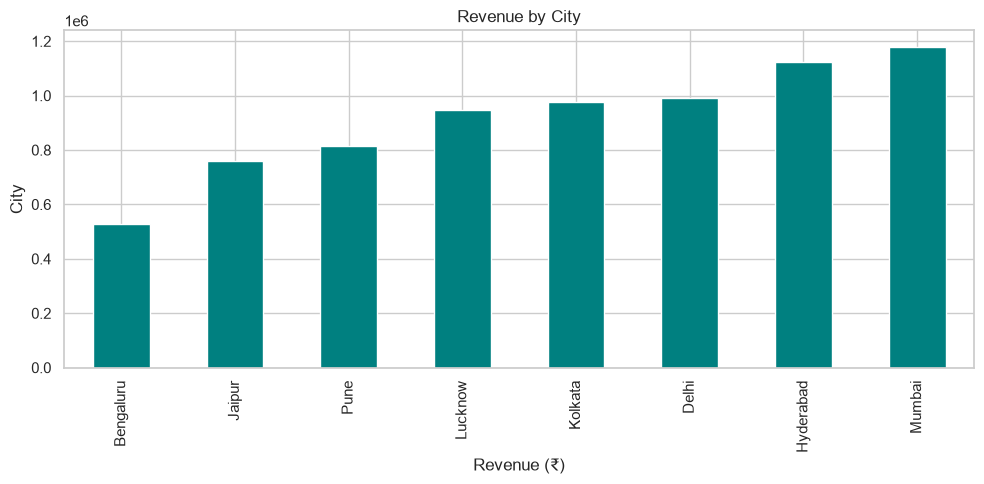

In [15]:
city_summary["revenue"].sort_values().plot(kind="bar",color="teal",title="Revenue by City")
plt.xlabel("Revenue (₹)"); plt.ylabel("City"); plt.tight_layout(); plt.show()

### 9.5 Scatter plot: purchase frequency vs total spend

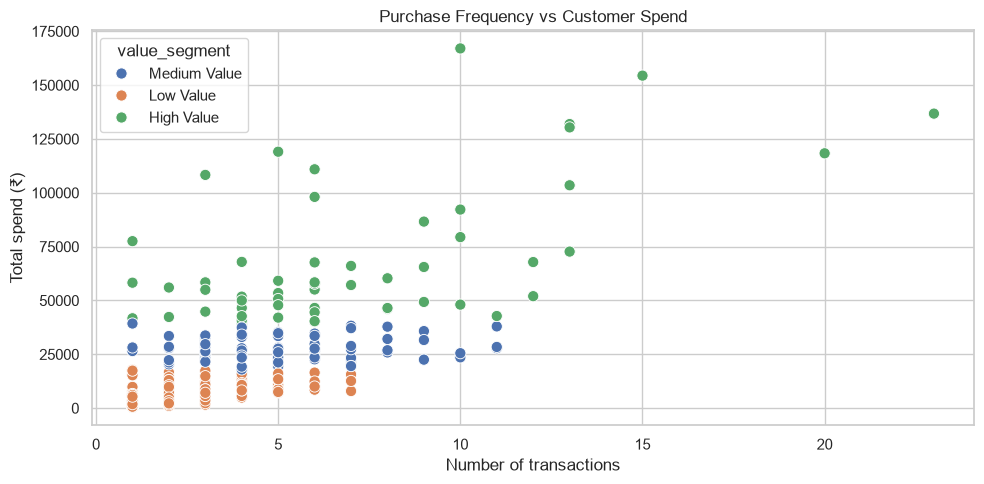

In [16]:
sns.scatterplot(data=customer_summary,x="transactions",y="total_spend",hue="value_segment",s=65)
plt.title("Purchase Frequency vs Customer Spend"); plt.xlabel("Number of transactions")
plt.ylabel("Total spend (₹)"); plt.tight_layout(); plt.show()

## 10. Bonus: Marketing strategies based on analysis

In [17]:
top_category=category_summary["revenue"].idxmax()
top_city=city_summary["revenue"].idxmax()
top_age_group=age_summary.sort_values("revenue",ascending=False).iloc[0]["age_group"]
high_value_count=int((customer_summary["value_segment"]=="High Value").sum())
print("DATA-BASED MARKETING SUGGESTIONS")
print(f"1. Feature {top_category}, the top revenue category, in targeted campaigns.")
print(f"2. Prioritize {top_city} for a location-focused campaign.")
print(f"3. Tailor offers to age group {top_age_group}, the highest-revenue age segment.")
print(f"4. Reward {high_value_count} high-value customers with loyalty points and early access.")
print("5. Use relevant product bundles and personalized recommendations.")
print("6. A/B test campaign messages and measure conversion and revenue.")
print("Note: These recommendations are based on synthetic practice data, not real customer behaviour.")

DATA-BASED MARKETING SUGGESTIONS
1. Feature Electronics, the top revenue category, in targeted campaigns.
2. Prioritize Mumbai for a location-focused campaign.
3. Tailor offers to age group 46–55, the highest-revenue age segment.
4. Reward 57 high-value customers with loyalty points and early access.
5. Use relevant product bundles and personalized recommendations.
6. A/B test campaign messages and measure conversion and revenue.
Note: These recommendations are based on synthetic practice data, not real customer behaviour.


## 11. Conclusion

Write 3–5 observations from your actual outputs: leading product category, highest-revenue city, strongest age group, and high-value customer characteristics. Clearly state that this is synthetic practice data.

## 12. Export cleaned data and summaries

In [18]:
data.to_csv("customer_data_cleaned.csv",index=False)
customer_summary.to_csv("customer_segments.csv",index=False)
category_summary.to_csv("category_revenue_summary.csv")
city_summary.to_csv("city_revenue_summary.csv")
print("Saved output files in:",Path.cwd())

Saved output files in: D:\OneDrive\DA_Project\Task_4_customer_Data_Analysis
